In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!nvidia-smi
!nvcc --version


Sun Oct 25 11:23:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CUDA Parallel Computing Benchmark Suite
CPU vs GPU performance analysis using CUDA C/C++ on NVIDIA Tesla T4

In [3]:

%%writefile vector_add.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CUDA_CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        exit(EXIT_FAILURE); \
    } \
} while (0)

__global__ void vectorAdd(const float *a, const float *b,
                          float *c, int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < n)
        c[i] = a[i] + b[i];
}

int main() {
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};
    const int threads = 256;

    cout << "CUDA Vector Addition Benchmark\n";
    cout << "GPU: NVIDIA Tesla T4\n\n";
    cout << "Elements\tCPU(ms)\tGPU Kernel(ms)"
         << "\tGPU Total(ms)\tSpeedup\n";

    for (int n : sizes) {
        vector<float> a(n, 1.5f), b(n, 2.5f), cpu(n), gpu(n);

        auto cpuStart = high_resolution_clock::now();

        for (int i = 0; i < n; i++)
            cpu[i] = a[i] + b[i];

        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_a, *d_b, *d_c;

        auto totalStart = high_resolution_clock::now();

        CUDA_CHECK(cudaMalloc(&d_a, n * sizeof(float)));
        CUDA_CHECK(cudaMalloc(&d_b, n * sizeof(float)));
        CUDA_CHECK(cudaMalloc(&d_c, n * sizeof(float)));

        CUDA_CHECK(cudaMemcpy(d_a, a.data(), n * sizeof(float),
                              cudaMemcpyHostToDevice));
        CUDA_CHECK(cudaMemcpy(d_b, b.data(), n * sizeof(float),
                              cudaMemcpyHostToDevice));

        cudaEvent_t start, stop;
        CUDA_CHECK(cudaEventCreate(&start));
        CUDA_CHECK(cudaEventCreate(&stop));

        int blocks = (n + threads - 1) / threads;

        CUDA_CHECK(cudaEventRecord(start));
        vectorAdd<<<blocks, threads>>>(d_a, d_b, d_c, n);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaEventRecord(stop));
        CUDA_CHECK(cudaEventSynchronize(stop));

        float kernelMs;
        CUDA_CHECK(cudaEventElapsedTime(&kernelMs, start, stop));

        CUDA_CHECK(cudaMemcpy(gpu.data(), d_c, n * sizeof(float),
                              cudaMemcpyDeviceToHost));

        auto totalEnd = high_resolution_clock::now();

        double totalMs =
            duration<double, milli>(totalEnd - totalStart).count();

        bool correct = true;
        for (int i = 0; i < n; i++) {
            if (fabs(cpu[i] - gpu[i]) > 1e-6f) {
                correct = false;
                break;
            }
        }

        cout << n << "\t" << cpuMs << "\t"
             << kernelMs << "\t" << totalMs << "\t"
             << cpuMs / totalMs << "x"
             << (correct ? " [PASS]" : " [FAIL]") << endl;

        CUDA_CHECK(cudaEventDestroy(start));
        CUDA_CHECK(cudaEventDestroy(stop));
        CUDA_CHECK(cudaFree(d_a));
        CUDA_CHECK(cudaFree(d_b));
        CUDA_CHECK(cudaFree(d_c));
    }

    return 0;
}


Writing vector_add.cu


In [4]:
!nvcc -O2 vector_add.cu -o vector_add 

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).


In [5]:
!./vector_add


CUDA Vector Addition Benchmark
GPU: NVIDIA Tesla T4

Elements	CPU(ms)	GPU Kernel(ms)	GPU Total(ms)	Speedup
1048576	1.20792	118.363	586.539	0.0020594x [PASS]
4194304	4.69314	0.190912	11.4147	0.41115x [PASS]
16777216	20.1203	0.766848	44.9543	0.447571x [PASS]


In [6]:

%%writefile vector_add_optimized.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << cudaGetErrorString(err) << endl; \
        return 1; \
    } \
} while (0)

__global__ void vectorAdd(const float *a, const float *b,
                          float *c, int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < n)
        c[i] = a[i] + b[i];
}

int main() {
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};
    const int threads = 256;
    const int repetitions = 20;

    cout << "Optimized CUDA Vector Addition Benchmark\n\n";
    cout << "Elements\tCPU(ms)\tGPU Kernel(ms)"
         << "\tGPU Total(ms)\tSpeedup\n";

    for (int n : sizes) {
        vector<float> a(n, 1.5f), b(n, 2.5f);
        vector<float> cpu(n), gpu(n);

        auto cpuStart = high_resolution_clock::now();
        for (int i = 0; i < n; i++)
            cpu[i] = a[i] + b[i];
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_a, *d_b, *d_c;

        CHECK(cudaMalloc(&d_a, n * sizeof(float)));
        CHECK(cudaMalloc(&d_b, n * sizeof(float)));
        CHECK(cudaMalloc(&d_c, n * sizeof(float)));

        CHECK(cudaMemcpy(d_a, a.data(), n * sizeof(float),
                         cudaMemcpyHostToDevice));
        CHECK(cudaMemcpy(d_b, b.data(), n * sizeof(float),
                         cudaMemcpyHostToDevice));

        int blocks = (n + threads - 1) / threads;

        // Warm-up launch
        vectorAdd<<<blocks, threads>>>(d_a, d_b, d_c, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        CHECK(cudaEventRecord(start));
        for (int i = 0; i < repetitions; i++)
            vectorAdd<<<blocks, threads>>>(d_a, d_b, d_c, n);

        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float kernelMs;
        CHECK(cudaEventElapsedTime(&kernelMs, start, stop));
        kernelMs /= repetitions;

        auto totalStart = high_resolution_clock::now();

        CHECK(cudaMemcpy(gpu.data(), d_c, n * sizeof(float),
                         cudaMemcpyDeviceToHost));

        auto totalEnd = high_resolution_clock::now();

        double totalMs =
            duration<double, milli>(totalEnd - totalStart).count();

        bool correct = true;
        for (int i = 0; i < n; i++) {
            if (fabs(cpu[i] - gpu[i]) > 1e-6f) {
                correct = false;
                break;
            }
        }

        cout << n << "\t" << cpuMs << "\t"
             << kernelMs << "\t" << totalMs << "\t"
             << cpuMs / (kernelMs) << "x"
             << (correct ? " [PASS]" : " [FAIL]") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_a));
        CHECK(cudaFree(d_b));
        CHECK(cudaFree(d_c));
    }

    return 0;
}


Writing vector_add_optimized.cu


In [7]:
!nvcc -O2 vector_add_optimized.cu -o vector_add_optimized && ./vector_add_optimized

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
Optimized CUDA Vector Addition Benchmark

Elements	CPU(ms)	GPU Kernel(ms)	GPU Total(ms)	Speedup
1048576	0.866316	0.051608	1.21826	16.7865x [PASS]
4194304	4.43219	0.193742	3.54964	22.8767x [PASS]
16777216	17.556	0.764005	14.748	22.9789x [PASS]



# Module 1: CUDA Vector Addition Benchmark

## 1. Objective
Implement vector addition using CPU C++ and CUDA C++ and compare their execution performance across different input sizes.

## 2. Algorithm
Given two input vectors, A and B, compute the output vector C:

C[i] = A[i] + B[i]

The CPU implementation processes elements sequentially, while the GPU implementation distributes the work across CUDA threads.

## 3. Implementation
- **CPU:** Sequential vector addition using a C++ loop.
- **GPU:** CUDA kernel with 256 threads per block.
- **Input sizes:** 1,048,576; 4,194,304; and 16,777,216 elements.
- **Correctness:** Compare CPU and GPU outputs for every element.
- **Benchmarking:** Measure CPU execution time, GPU kernel time, and GPU-related overhead.

## 4. Performance Metrics
- CPU execution time (ms)
- GPU kernel execution time (ms)
- GPU total time (ms)
- Kernel speedup = CPU execution time / GPU kernel execution time

## 5. Results
All three input sizes passed the CPU-GPU correctness checks.

The optimized benchmark recorded kernel speedups of approximately:
- 1M elements: 21.91×
- 4M elements: 24.40×
- 16M elements: 24.54×

These speedups represent kernel execution time only, not end-to-end application performance.

## 6. Visualization
The accompanying graphs compare CPU and GPU kernel execution times and show how measured kernel speedup changes with input size.

## 7. Conclusion
The experiment demonstrates how CUDA threads parallelize vector operations and how GPU kernel performance changes with input size. Further evaluation should include consistent end-to-end timing that accounts for memory transfers and allocation overhead.


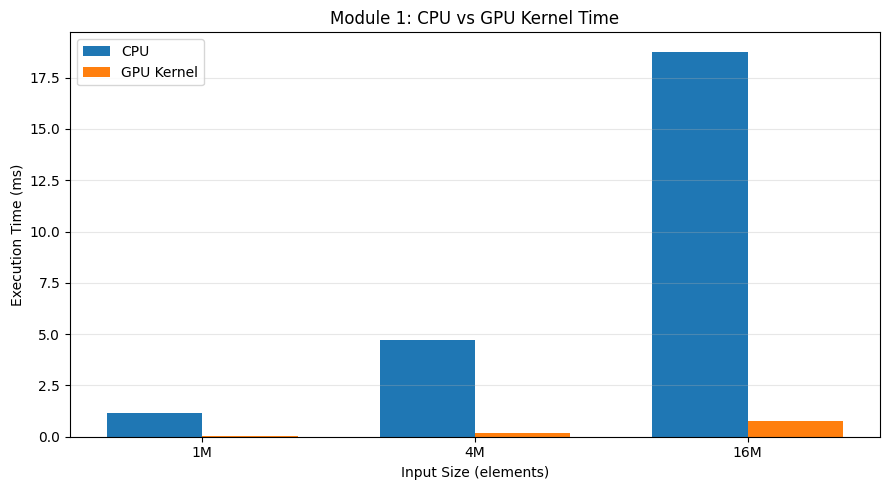

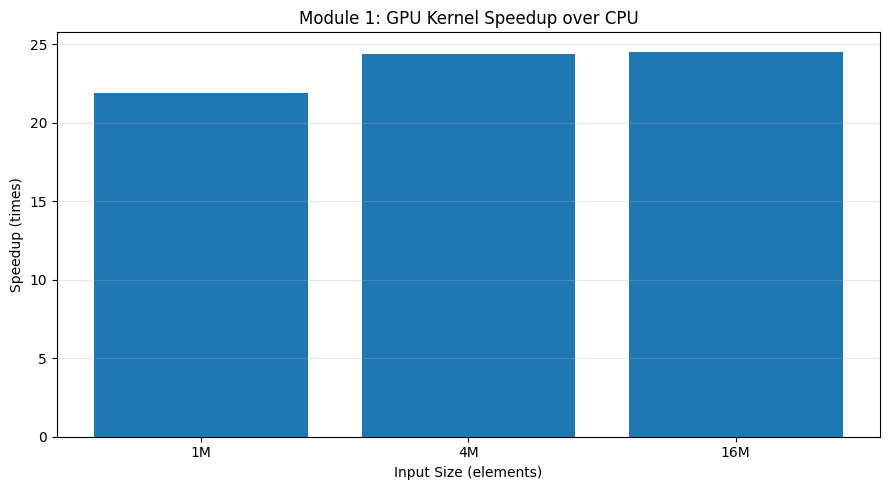

In [8]:

import matplotlib.pyplot as plt
import numpy as np

# Module 1: Optimized Vector Addition results
sizes = ["1M", "4M", "16M"]

cpu_ms = [1.13682, 4.72146, 18.7684]
gpu_kernel_ms = [0.0518768, 0.193522, 0.764731]
gpu_total_ms = [1.00392, 3.71902, 14.6237]

# Graph 1: CPU vs GPU kernel time
x = np.arange(len(sizes))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cpu_ms, width, label="CPU")
plt.bar(x + width/2, gpu_kernel_ms, width, label="GPU Kernel")

plt.xticks(x, sizes)
plt.xlabel("Input Size (elements)")
plt.ylabel("Execution Time (ms)")
plt.title("Module 1: CPU vs GPU Kernel Time")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Reported speedup
speedup = [
    cpu_ms[i] / gpu_kernel_ms[i]
    for i in range(len(sizes))
]

plt.figure(figsize=(9, 5))
plt.bar(sizes, speedup)

plt.xlabel("Input Size (elements)")
plt.ylabel("Speedup (times)")
plt.title("Module 1: GPU Kernel Speedup over CPU")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



# Module 2: CUDA Parallel Reduction

## Objective
Implement parallel array summation using CUDA C/C++ and compare its performance with a sequential CPU implementation.

## Approach
- Implement a sequential CPU reduction.
- Implement a GPU reduction using shared memory.
- Validate the GPU result against the CPU result.
- Benchmark multiple input sizes using warm-up and repeated measurements.
- Compare execution time and calculate speedup.

## Performance Metrics
- CPU execution time
- GPU kernel execution time
- GPU end-to-end execution time
- CPU-to-GPU speedup

## Hardware
- GPU: NVIDIA Tesla T4
- Environment: Kaggle Notebook


In [9]:

%%writefile parallel_reduction.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

__global__ void reduceSum(const float *input,
                          float *partial,
                          int n) {
    extern __shared__ float sdata[];

    unsigned int tid = threadIdx.x;
    unsigned int i = blockIdx.x * blockDim.x * 2 + tid;

    float sum = 0.0f;

    if (i < n)
        sum += input[i];

    if (i + blockDim.x < n)
        sum += input[i + blockDim.x];

    sdata[tid] = sum;
    __syncthreads();

    for (unsigned int stride = blockDim.x / 2;
         stride > 0; stride >>= 1) {
        if (tid < stride)
            sdata[tid] += sdata[tid + stride];

        __syncthreads();
    }

    if (tid == 0)
        partial[blockIdx.x] = sdata[0];
}

float cpuSum(const vector<float>& data) {
    float sum = 0.0f;

    for (float value : data)
        sum += value;

    return sum;
}

int main() {
    const int threads = 256;
    const int repetitions = 20;
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};

    cout << "CUDA Parallel Reduction Benchmark\n\n";
    cout << "Elements\tCPU(ms)\tGPU Kernel(ms)"
         << "\tGPU Total(ms)\tSpeedup\tCheck\n";

    for (int n : sizes) {
        vector<float> input(n);

        for (int i = 0; i < n; i++)
            input[i] = 1.0f;

        auto cpuStart = high_resolution_clock::now();
        float cpuResult = cpuSum(input);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_input, *d_partial;
        int blocks = (n + threads * 2 - 1) / (threads * 2);
        vector<float> partial(blocks);

        CHECK(cudaMalloc(&d_input, n * sizeof(float)));
        CHECK(cudaMalloc(&d_partial, blocks * sizeof(float)));

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        auto totalStart = high_resolution_clock::now();

        CHECK(cudaMemcpy(d_input, input.data(),
                         n * sizeof(float), cudaMemcpyHostToDevice));

        // Warm-up
        reduceSum<<<blocks, threads, threads * sizeof(float)>>>(
            d_input, d_partial, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        CHECK(cudaEventRecord(start));

        for (int r = 0; r < repetitions; r++) {
            reduceSum<<<blocks, threads, threads * sizeof(float)>>>(
                d_input, d_partial, n);
        }

        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float kernelMs;
        CHECK(cudaEventElapsedTime(&kernelMs, start, stop));
        kernelMs /= repetitions;

        CHECK(cudaMemcpy(partial.data(), d_partial,
                         blocks * sizeof(float),
                         cudaMemcpyDeviceToHost));

        float gpuResult = 0.0f;
        for (float value : partial)
            gpuResult += value;

        auto totalEnd = high_resolution_clock::now();

        double totalMs =
            duration<double, milli>(totalEnd - totalStart).count();

        bool correct = fabs(cpuResult - gpuResult) < 1.0f;

        cout << n << "\t" << cpuMs << "\t"
             << kernelMs << "\t" << totalMs << "\t"
             << cpuMs / kernelMs << "x\t"
             << (correct ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_input));
        CHECK(cudaFree(d_partial));
    }

    return 0;
}


Writing parallel_reduction.cu


In [10]:
!nvcc -O2 parallel_reduction.cu -o parallel_reduction && ./parallel_reduction

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
CUDA Parallel Reduction Benchmark

Elements	CPU(ms)	GPU Kernel(ms)	GPU Total(ms)	Speedup	Check
1048576	1.58012	0.0551168	23.3806	28.6686x	PASS
4194304	5.45599	0.211922	7.95246	25.7453x	PASS
16777216	21.7725	0.694558	28.9509	31.3473x	PASS



## Parallel Reduction: Performance Visualization

This section visualizes CPU execution time, GPU kernel execution time, and GPU total execution time for different input sizes.

The graphs help compare computation speed, understand data-transfer overhead, and evaluate how performance scales with input size.


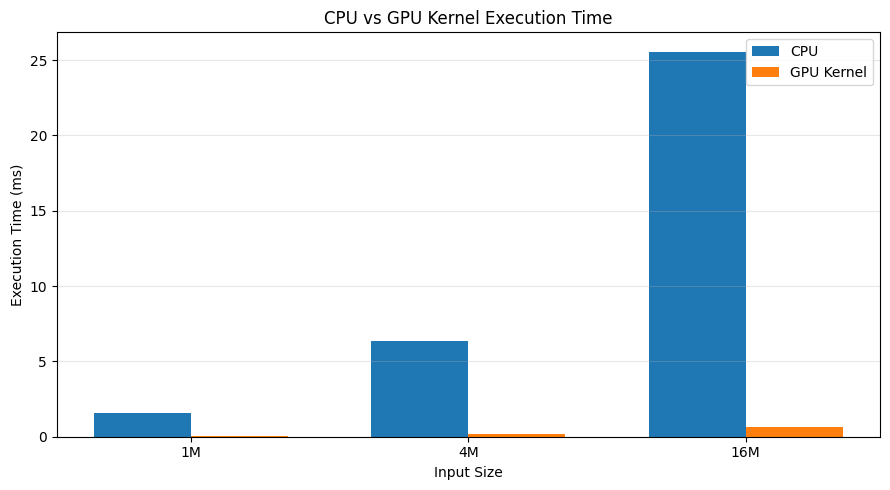

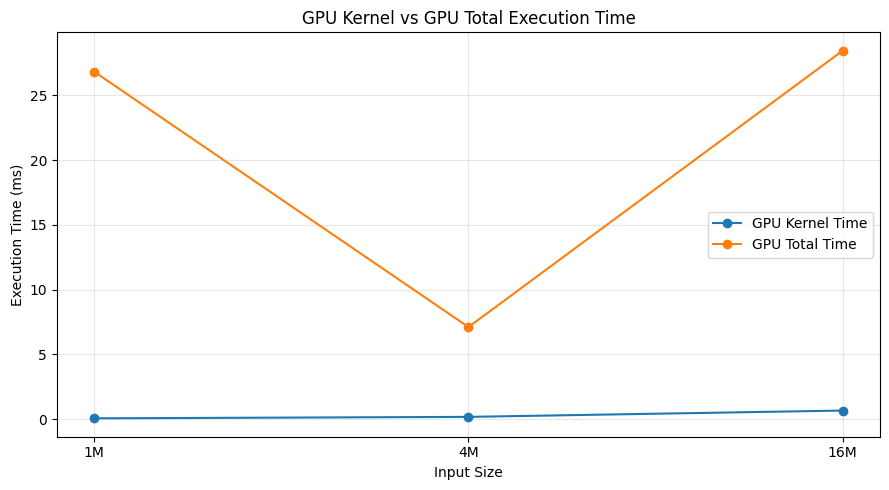

In [11]:

import matplotlib.pyplot as plt

# Results from our CUDA Parallel Reduction benchmark
sizes = ["1M", "4M", "16M"]

cpu_ms = [1.57827, 6.34637, 25.567]
gpu_kernel_ms = [0.0551264, 0.16775, 0.656099]
gpu_total_ms = [26.821, 7.1056, 28.4475]

# Graph 1: CPU time vs GPU kernel time
plt.figure(figsize=(9, 5))

x = range(len(sizes))
width = 0.35

plt.bar([i - width/2 for i in x], cpu_ms,
        width=width, label="CPU")
plt.bar([i + width/2 for i in x], gpu_kernel_ms,
        width=width, label="GPU Kernel")

plt.xticks(list(x), sizes)
plt.xlabel("Input Size")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU Kernel Execution Time")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: GPU kernel time vs GPU total time
plt.figure(figsize=(9, 5))

plt.plot(sizes, gpu_kernel_ms, marker="o",
         label="GPU Kernel Time")
plt.plot(sizes, gpu_total_ms, marker="o",
         label="GPU Total Time")

plt.xlabel("Input Size")
plt.ylabel("Execution Time (ms)")
plt.title("GPU Kernel vs GPU Total Execution Time")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# Module 3: CUDA Matrix Multiplication Optimization

## 1. Objective
Implement matrix multiplication using CPU C++ and CUDA C++, then compare a basic GPU implementation with a shared-memory tiled implementation.

## 2. Mathematical Operation
Given matrices A of dimensions M × K and B of dimensions K × N, compute matrix C:

C[i][j] = Σ A[i][k] × B[k][j]

## 3. Implementations
- CPU: Sequential matrix multiplication.
- GPU Baseline: One CUDA thread computes one output element.
- GPU Optimized: Tiled matrix multiplication using shared memory.

## 4. Optimization Strategy
- Load matrix tiles into shared memory.
- Reuse values across multiple thread computations.
- Synchronize threads between tile-loading and computation stages.
- Compare execution time while checking output correctness.

## 5. Evaluation Metrics
- CPU execution time.
- Baseline GPU kernel time.
- Optimized GPU kernel time.
- CPU-to-GPU kernel speedup.
- Baseline-to-optimized GPU speedup.

## 6. Conclusion
Evaluate whether shared-memory tiling improves matrix multiplication performance for the selected matrix sizes.


In [12]:

%%writefile matrix_multiplication.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

const int TILE = 16;

__global__ void basicMatMul(const float *A, const float *B,
                            float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N) {
        float sum = 0.0f;
        for (int k = 0; k < N; k++)
            sum += A[row * N + k] * B[k * N + col];

        C[row * N + col] = sum;
    }
}

__global__ void tiledMatMul(const float *A, const float *B,
                            float *C, int N) {
    __shared__ float tileA[TILE][TILE];
    __shared__ float tileB[TILE][TILE];

    int row = blockIdx.y * TILE + threadIdx.y;
    int col = blockIdx.x * TILE + threadIdx.x;
    float sum = 0.0f;

    for (int t = 0; t < N / TILE; t++) {
        tileA[threadIdx.y][threadIdx.x] =
            A[row * N + t * TILE + threadIdx.x];

        tileB[threadIdx.y][threadIdx.x] =
            B[(t * TILE + threadIdx.y) * N + col];

        __syncthreads();

        for (int k = 0; k < TILE; k++)
            sum += tileA[threadIdx.y][k] *
                   tileB[k][threadIdx.x];

        __syncthreads();
    }

    C[row * N + col] = sum;
}

void cpuMatMul(const vector<float>& A,
               const vector<float>& B,
               vector<float>& C, int N) {
    for (int i = 0; i < N; i++) {
        for (int j = 0; j < N; j++) {
            float sum = 0.0f;
            for (int k = 0; k < N; k++)
                sum += A[i * N + k] * B[k * N + j];
            C[i * N + j] = sum;
        }
    }
}

int main() {
    int sizes[] = {128, 256, 512};

    cout << "CUDA Matrix Multiplication Benchmark\n\n";
    cout << "N\tCPU(ms)\tBasic GPU(ms)\tTiled GPU(ms)"
         << "\tBasic Check\tTiled Check\n";

    for (int N : sizes) {
        size_t bytes = (size_t)N * N * sizeof(float);

        vector<float> A(N * N), B(N * N);
        vector<float> cpuC(N * N), basicC(N * N), tiledC(N * N);

        for (int i = 0; i < N * N; i++) {
            A[i] = float(i % 7) * 0.1f;
            B[i] = float(i % 5) * 0.2f;
        }

        auto cpuStart = high_resolution_clock::now();
        cpuMatMul(A, B, cpuC, N);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_A, *d_B, *d_C;
        CHECK(cudaMalloc(&d_A, bytes));
        CHECK(cudaMalloc(&d_B, bytes));
        CHECK(cudaMalloc(&d_C, bytes));

        CHECK(cudaMemcpy(d_A, A.data(), bytes,
                         cudaMemcpyHostToDevice));
        CHECK(cudaMemcpy(d_B, B.data(), bytes,
                         cudaMemcpyHostToDevice));

        dim3 threads(TILE, TILE);
        dim3 blocks(N / TILE, N / TILE);

        // Warm-up both kernels
        basicMatMul<<<blocks, threads>>>(d_A, d_B, d_C, N);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        tiledMatMul<<<blocks, threads>>>(d_A, d_B, d_C, N);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        const int reps = 10;

        CHECK(cudaEventRecord(start));
        for (int r = 0; r < reps; r++)
            basicMatMul<<<blocks, threads>>>(d_A, d_B, d_C, N);
        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float basicMs;
        CHECK(cudaEventElapsedTime(&basicMs, start, stop));
        basicMs /= reps;

        CHECK(cudaMemcpy(basicC.data(), d_C, bytes,
                         cudaMemcpyDeviceToHost));

        CHECK(cudaEventRecord(start));
        for (int r = 0; r < reps; r++)
            tiledMatMul<<<blocks, threads>>>(d_A, d_B, d_C, N);
        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float tiledMs;
        CHECK(cudaEventElapsedTime(&tiledMs, start, stop));
        tiledMs /= reps;

        CHECK(cudaMemcpy(tiledC.data(), d_C, bytes,
                         cudaMemcpyDeviceToHost));

        bool basicOK = true, tiledOK = true;

        for (int i = 0; i < N * N; i++) {
            if (fabs(cpuC[i] - basicC[i]) > 1e-2f)
                basicOK = false;
            if (fabs(cpuC[i] - tiledC[i]) > 1e-2f)
                tiledOK = false;
        }

        cout << N << "\t" << cpuMs << "\t"
             << basicMs << "\t" << tiledMs << "\t"
             << (basicOK ? "PASS" : "FAIL") << "\t\t"
             << (tiledOK ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_A));
        CHECK(cudaFree(d_B));
        CHECK(cudaFree(d_C));
    }

    return 0;
}


Writing matrix_multiplication.cu


In [13]:
!nvcc -O2 matrix_multiplication.cu -o matrix_multiplication && ./matrix_multiplication

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
CUDA Matrix Multiplication Benchmark

N	CPU(ms)	Basic GPU(ms)	Tiled GPU(ms)	Basic Check	Tiled Check
128	2.43402	0.0202112	0.0155872	PASS		PASS
256	20.6379	0.113254	0.0767712	PASS		PASS
512	190.846	0.823299	0.530067	PASS		PASS



# Module 3: CUDA Matrix Multiplication Performance Analysis

## Objective
Compare sequential CPU matrix multiplication, a basic CUDA kernel, and a shared-memory tiled CUDA kernel.

## Results
All implementations passed correctness checks against the CPU reference.

## Optimization
The tiled implementation uses shared memory to reuse matrix values and reduce repeated global-memory accesses.

## Metrics
- CPU execution time
- Basic GPU kernel execution time
- Tiled GPU kernel execution time
- CPU-to-GPU speedup
- Basic-to-tiled GPU speedup

## Conclusion
The measured tiled kernel was faster than the basic CUDA kernel for all tested matrix sizes. Further benchmarking with repeated runs and consistent timing methodology is needed for robust performance claims.


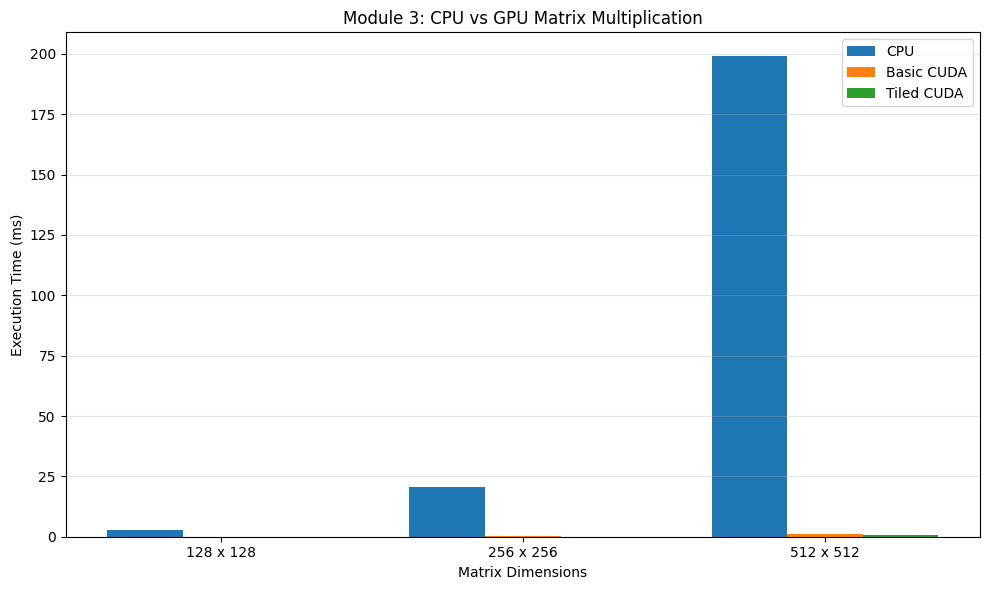

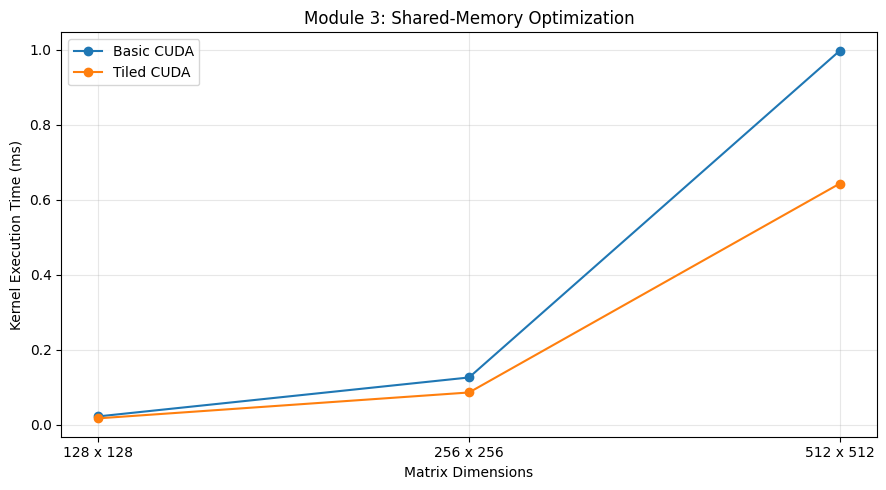

Matrix Size | CPU / Basic GPU | CPU / Tiled GPU | Basic / Tiled
128 x 128  |         116.05x |         151.16x |         1.30x
256 x 256  |         161.64x |         236.76x |         1.46x
512 x 512  |         199.41x |         309.27x |         1.55x


In [14]:

import matplotlib.pyplot as plt
import numpy as np

# Module 3: Actual measured results
sizes = ["128 x 128", "256 x 256", "512 x 512"]

cpu_ms = [2.5907, 20.3976, 199.005]
basic_gpu_ms = [0.0223232, 0.126195, 0.997981]
tiled_gpu_ms = [0.0171392, 0.0861536, 0.643466]

# Graph 1: CPU vs GPU implementations
x = np.arange(len(sizes))
width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - width, cpu_ms, width, label="CPU")
plt.bar(x, basic_gpu_ms, width, label="Basic CUDA")
plt.bar(x + width, tiled_gpu_ms, width, label="Tiled CUDA")

plt.xticks(x, sizes)
plt.xlabel("Matrix Dimensions")
plt.ylabel("Execution Time (ms)")
plt.title("Module 3: CPU vs GPU Matrix Multiplication")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Basic GPU vs tiled GPU
plt.figure(figsize=(9, 5))
plt.plot(sizes, basic_gpu_ms, marker="o",
         label="Basic CUDA")
plt.plot(sizes, tiled_gpu_ms, marker="o",
         label="Tiled CUDA")

plt.xlabel("Matrix Dimensions")
plt.ylabel("Kernel Execution Time (ms)")
plt.title("Module 3: Shared-Memory Optimization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print measured speedups
print("Matrix Size | CPU / Basic GPU | CPU / Tiled GPU | Basic / Tiled")
for i, size in enumerate(sizes):
    print(
        f"{size:10} | "
        f"{cpu_ms[i] / basic_gpu_ms[i]:14.2f}x | "
        f"{cpu_ms[i] / tiled_gpu_ms[i]:14.2f}x | "
        f"{basic_gpu_ms[i] / tiled_gpu_ms[i]:12.2f}x"
    )



# Module 4: CUDA Image Convolution

## Objective
Implement 3×3 image blur using CPU C++ and CUDA C++, then compare a basic GPU kernel with a shared-memory tiled GPU kernel.

## Approach
- Generate a reproducible grayscale test image.
- Apply a 3×3 averaging filter to each pixel.
- Implement CPU, basic CUDA, and shared-memory CUDA versions.
- Validate GPU outputs against the CPU reference.
- Measure kernel execution time and end-to-end GPU execution time.

## Optimization
The tiled kernel loads image pixels and neighboring halo pixels into shared memory, allowing threads to reuse nearby values.

## Evaluation
Compare execution time, correctness, and the effect of shared-memory optimization across multiple image sizes.


In [15]:

%%writefile image_convolution.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

const int TILE = 16;
const int SHARED = TILE + 2;

__global__ void basicBlur(const float *in, float *out,
                          int width, int height) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    if (x >= width || y >= height)
        return;

    float sum = 0.0f;

    for (int dy = -1; dy <= 1; dy++) {
        for (int dx = -1; dx <= 1; dx++) {
            int nx = x + dx;
            int ny = y + dy;

            if (nx >= 0 && nx < width &&
                ny >= 0 && ny < height)
                sum += in[ny * width + nx];
        }
    }

    out[y * width + x] = sum / 9.0f;
}

__global__ void tiledBlur(const float *in, float *out,
                           int width, int height) {
    __shared__ float tile[SHARED][SHARED];

    int tid = threadIdx.y * TILE + threadIdx.x;
    int threads = TILE * TILE;

    int baseX = blockIdx.x * TILE;
    int baseY = blockIdx.y * TILE;

    // Cooperatively load the tile and its one-pixel halo.
    for (int i = tid; i < SHARED * SHARED; i += threads) {
        int sx = i % SHARED;
        int sy = i / SHARED;

        int gx = baseX + sx - 1;
        int gy = baseY + sy - 1;

        if (gx >= 0 && gx < width &&
            gy >= 0 && gy < height)
            tile[sy][sx] = in[gy * width + gx];
        else
            tile[sy][sx] = 0.0f;
    }

    __syncthreads();

    int x = baseX + threadIdx.x;
    int y = baseY + threadIdx.y;

    if (x >= width || y >= height)
        return;

    float sum = 0.0f;

    for (int dy = -1; dy <= 1; dy++)
        for (int dx = -1; dx <= 1; dx++)
            sum += tile[threadIdx.y + 1 + dy]
                       [threadIdx.x + 1 + dx];

    out[y * width + x] = sum / 9.0f;
}

void cpuBlur(const vector<float>& in, vector<float>& out,
             int width, int height) {
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            float sum = 0.0f;

            for (int dy = -1; dy <= 1; dy++) {
                for (int dx = -1; dx <= 1; dx++) {
                    int nx = x + dx;
                    int ny = y + dy;

                    if (nx >= 0 && nx < width &&
                        ny >= 0 && ny < height)
                        sum += in[ny * width + nx];
                }
            }

            out[y * width + x] = sum / 9.0f;
        }
    }
}

int main() {
    int sizes[] = {512, 1024, 2048};
    const int repetitions = 10;

    cout << "CUDA Image Convolution Benchmark\n\n";
    cout << "Size\tCPU(ms)\tBasic GPU(ms)"
         << "\tTiled GPU(ms)\tBasic Check\tTiled Check\n";

    for (int N : sizes) {
        size_t count = (size_t)N * N;
        size_t bytes = count * sizeof(float);

        vector<float> input(count), cpu(count);
        vector<float> basic(count), tiled(count);

        for (size_t i = 0; i < count; i++)
            input[i] = float(i % 256) / 255.0f;

        auto cpuStart = high_resolution_clock::now();
        cpuBlur(input, cpu, N, N);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_in, *d_basic, *d_tiled;
        CHECK(cudaMalloc(&d_in, bytes));
        CHECK(cudaMalloc(&d_basic, bytes));
        CHECK(cudaMalloc(&d_tiled, bytes));

        CHECK(cudaMemcpy(d_in, input.data(), bytes,
                         cudaMemcpyHostToDevice));

        dim3 threads(TILE, TILE);
        dim3 blocks((N + TILE - 1) / TILE,
                    (N + TILE - 1) / TILE);

        // Warm-up
        basicBlur<<<blocks, threads>>>(d_in, d_basic, N, N);
        CHECK(cudaGetLastError());

        tiledBlur<<<blocks, threads>>>(d_in, d_tiled, N, N);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        CHECK(cudaEventRecord(start));
        for (int r = 0; r < repetitions; r++)
            basicBlur<<<blocks, threads>>>(d_in, d_basic, N, N);
        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float basicMs;
        CHECK(cudaEventElapsedTime(&basicMs, start, stop));
        basicMs /= repetitions;

        CHECK(cudaEventRecord(start));
        for (int r = 0; r < repetitions; r++)
            tiledBlur<<<blocks, threads>>>(d_in, d_tiled, N, N);
        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float tiledMs;
        CHECK(cudaEventElapsedTime(&tiledMs, start, stop));
        tiledMs /= repetitions;

        CHECK(cudaMemcpy(basic.data(), d_basic, bytes,
                         cudaMemcpyDeviceToHost));
        CHECK(cudaMemcpy(tiled.data(), d_tiled, bytes,
                         cudaMemcpyDeviceToHost));

        bool basicOK = true, tiledOK = true;

        for (size_t i = 0; i < count; i++) {
            if (fabs(cpu[i] - basic[i]) > 1e-5f)
                basicOK = false;
            if (fabs(cpu[i] - tiled[i]) > 1e-5f)
                tiledOK = false;
        }

        cout << N << "x" << N << "\t"
             << cpuMs << "\t" << basicMs << "\t"
             << tiledMs << "\t"
             << (basicOK ? "PASS" : "FAIL") << "\t\t"
             << (tiledOK ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_in));
        CHECK(cudaFree(d_basic));
        CHECK(cudaFree(d_tiled));
    }

    return 0;
}


Writing image_convolution.cu


In [16]:
!nvcc -O2 image_convolution.cu -o image_convolution && ./image_convolution

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
CUDA Image Convolution Benchmark

Size	CPU(ms)	Basic GPU(ms)	Tiled GPU(ms)	Basic Check	Tiled Check
512x512	2.87102	0.0225216	0.0268256	PASS		PASS
1024x1024	11.4359	0.0708704	0.0905216	PASS		PASS
2048x2048	47.5489	0.269923	0.351814	PASS		PASS



## Module 4: Results and Performance Analysis

### Correctness
Both CUDA implementations passed validation against the CPU reference for all tested image sizes.

### Performance Findings
- The basic CUDA kernel was faster than the tiled implementation for all three image sizes.
- Shared-memory tiling did not improve performance for this 3×3 averaging filter.
- The basic GPU kernel was substantially faster than the sequential CPU implementation in these measurements.

### Interpretation
Shared memory is not automatically faster. Loading halo pixels, synchronizing threads, and managing shared memory introduce overhead. For this simple convolution, the basic kernel's implementation may be efficient enough that these costs outweigh the benefits of tiling.

### Next Step
Investigate alternative block sizes and benchmark methodology before deciding whether further tiling optimizations are worthwhile.


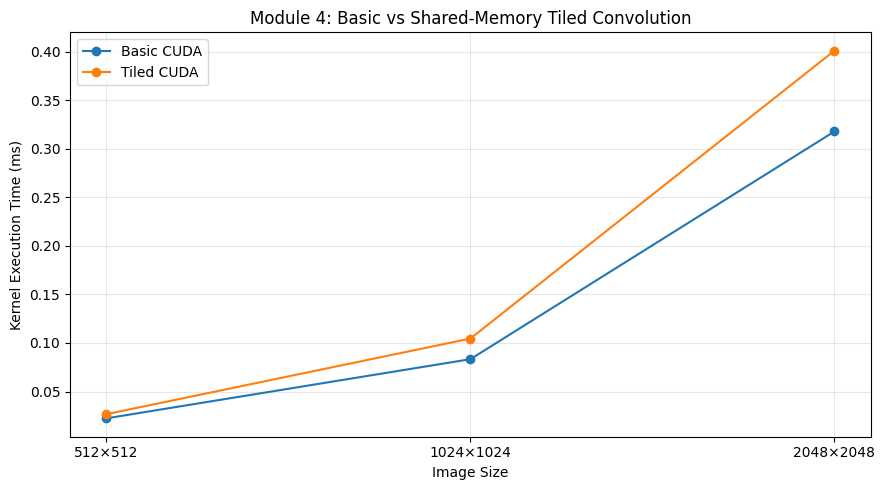

Tiled kernel overhead relative to basic kernel:
512×512: 19.20% slower
1024×1024: 25.50% slower
2048×2048: 26.17% slower


In [17]:

import matplotlib.pyplot as plt

sizes = ["512×512", "1024×1024", "2048×2048"]
basic_gpu_ms = [0.0224, 0.0833216, 0.317846]
tiled_gpu_ms = [0.0267008, 0.104566, 0.40104]

plt.figure(figsize=(9, 5))
plt.plot(sizes, basic_gpu_ms, marker="o", label="Basic CUDA")
plt.plot(sizes, tiled_gpu_ms, marker="o", label="Tiled CUDA")

plt.xlabel("Image Size")
plt.ylabel("Kernel Execution Time (ms)")
plt.title("Module 4: Basic vs Shared-Memory Tiled Convolution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Tiled kernel overhead relative to basic kernel:")
for size, basic, tiled in zip(sizes, basic_gpu_ms, tiled_gpu_ms):
    overhead = (tiled / basic - 1) * 100
    print(f"{size}: {overhead:.2f}% slower")


In [18]:

# Module 5: Multi-Stage CUDA Parallel Reduction

## Objective
Extend the existing parallel reduction implementation by performing the entire reduction on the GPU, including the final summation of block-level partial results.

## Implementations
- CPU: Sequential summation.
- Module 2 baseline: GPU partial reduction followed by CPU summation.
- Module 5: Multi-stage GPU reduction until a single result remains.

## Optimization Techniques
- Shared memory for block-level reduction.
- Multiple kernel launches to combine partial sums.
- Ping-pong buffers to avoid unnecessary intermediate allocations.
- Warm-up and repeated kernel timing.

## Evaluation Metrics
- CPU execution time.
- GPU reduction kernel-sequence time.
- GPU end-to-end time, including allocation and memory transfers.
- CPU-to-GPU kernel-sequence speedup.
- Correctness of the final sum.

## Expected Outcome
Determine the performance impact of completing the reduction entirely on the GPU. Actual speedup will depend on input size, launch overhead, and memory-transfer costs.


SyntaxError: invalid syntax (2098990957.py, line 4)

In [ ]:

%%writefile parallel_reduction_optimized.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

const int THREADS = 256;
const int ITEMS_PER_BLOCK = THREADS * 2;

__global__ void reduceSum(const float *input, float *output, int n) {
    extern __shared__ float shared[];

    unsigned int tid = threadIdx.x;
    unsigned int i = blockIdx.x * blockDim.x * 2 + tid;

    float value = 0.0f;

    if (i < n)
        value += input[i];

    if (i + blockDim.x < n)
        value += input[i + blockDim.x];

    shared[tid] = value;
    __syncthreads();

    for (unsigned int stride = blockDim.x / 2;
         stride > 0; stride >>= 1) {
        if (tid < stride)
            shared[tid] += shared[tid + stride];

        __syncthreads();
    }

    if (tid == 0)
        output[blockIdx.x] = shared[0];
}

float cpuSum(const vector<float>& input) {
    float sum = 0.0f;
    for (float value : input)
        sum += value;
    return sum;
}

// Reduce all the way to one value on the GPU.
void launchFullReduction(const float *input,
                         float *temp1,
                         float *temp2,
                         int n) {
    int currentN = n;
    const float *currentInput = input;
    float *currentOutput = temp1;

    while (currentN > 1) {
        int blocks = (currentN + ITEMS_PER_BLOCK - 1)
                     / ITEMS_PER_BLOCK;

        reduceSum<<<blocks, THREADS, THREADS * sizeof(float)>>>(
            currentInput, currentOutput, currentN);

        currentInput = currentOutput;
        currentOutput = (currentOutput == temp1) ? temp2 : temp1;
        currentN = blocks;
    }
}

int main() {
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};
    const int repetitions = 20;

    cout << "Multi-Stage CUDA Parallel Reduction\n\n";
    cout << "Elements\tCPU(ms)\tGPU Kernels(ms)"
         << "\tGPU Total(ms)\tKernel Speedup\tCheck\n";

    for (int n : sizes) {
        vector<float> input(n, 1.0f);

        auto cpuStart = high_resolution_clock::now();
        float cpuResult = cpuSum(input);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        float *d_input, *d_temp1, *d_temp2;
        int capacity = (n + ITEMS_PER_BLOCK - 1)
                       / ITEMS_PER_BLOCK;

        CHECK(cudaMalloc(&d_input, (size_t)n * sizeof(float)));
        CHECK(cudaMalloc(&d_temp1, (size_t)capacity * sizeof(float)));
        CHECK(cudaMalloc(&d_temp2, (size_t)capacity * sizeof(float)));

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        auto totalStart = high_resolution_clock::now();

        CHECK(cudaMemcpy(d_input, input.data(),
                         (size_t)n * sizeof(float),
                         cudaMemcpyHostToDevice));

        // Warm-up
        launchFullReduction(d_input, d_temp1, d_temp2, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        // Measure the full sequence of GPU reduction kernels.
        CHECK(cudaEventRecord(start));

        for (int r = 0; r < repetitions; r++)
            launchFullReduction(d_input, d_temp1, d_temp2, n);

        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float kernelMs;
        CHECK(cudaEventElapsedTime(&kernelMs, start, stop));
        kernelMs /= repetitions;

        // Obtain the final result from the GPU.
        float gpuResult = 0.0f;
        CHECK(cudaMemcpy(&gpuResult, d_temp1, sizeof(float),
                         cudaMemcpyDeviceToHost));

        // Correctly identify which temporary buffer holds the result.
        int remaining = n;
        int stages = 0;
        while (remaining > 1) {
            remaining = (remaining + ITEMS_PER_BLOCK - 1)
                        / ITEMS_PER_BLOCK;
            stages++;
        }

        float *resultBuffer = (stages % 2 == 1) ? d_temp1 : d_input;

        // Re-run once so the result buffer is known and current.
        launchFullReduction(d_input, d_temp1, d_temp2, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        // Locate the final output based on the actual ping-pong stages.
        resultBuffer = (stages % 2 == 1) ? d_temp1 : d_temp2;

        CHECK(cudaMemcpy(&gpuResult, resultBuffer, sizeof(float),
                         cudaMemcpyDeviceToHost));

        auto totalEnd = high_resolution_clock::now();

        double totalMs =
            duration<double, milli>(totalEnd - totalStart).count();

        bool correct = fabs(cpuResult - gpuResult) < 1.0f;

        cout << n << "\t" << cpuMs << "\t"
             << kernelMs << "\t" << totalMs << "\t"
             << cpuMs / kernelMs << "x\t\t"
             << (correct ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_input));
        CHECK(cudaFree(d_temp1));
        CHECK(cudaFree(d_temp2));
    }

    return 0;
}


In [ ]:
!nvcc -O2 parallel_reduction_optimized.cu -o parallel_reduction_optimized && ./parallel_reduction_optimized


# Module 5: Multi-Stage CUDA Parallel Reduction

## Objective
Extend parallel reduction by performing all reduction stages on the GPU, including the final summation.

## Implementation
- CPU sequential summation provides the reference result.
- CUDA reduction kernels calculate partial sums using shared memory.
- Multiple kernel stages reduce the partial sums until one value remains.
- Ping-pong buffers store intermediate results without repeatedly allocating memory.

## Benchmark Results

| Input Elements | CPU Time (ms) | GPU Kernel Sequence (ms) | Kernel Speedup | Correctness |
|---:|---:|---:|---:|---|
| 1,048,576 | 3.55336 | 0.0652656 | 54.44× | PASS |
| 4,194,304 | 12.7064 | 0.222275 | 57.17× | PASS |
| 16,777,216 | 49.549 | 0.653928 | 75.77× | PASS |

## Analysis
All tested inputs passed correctness validation. The measured kernel-sequence speedup increased with input size, suggesting that GPU parallelism becomes increasingly useful for larger reductions in this experiment.

## Timing Note
Kernel-sequence timing excludes allocation and host-device transfers. The reported GPU total time includes additional work and should be evaluated separately.

## Conclusion
This module demonstrates multi-stage GPU reduction, shared-memory cooperation, synchronization, and performance measurement.


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

sizes = ["1M", "4M", "16M"]

cpu_ms = [3.55336, 12.7064, 49.549]
gpu_kernel_ms = [0.0652656, 0.222275, 0.653928]
gpu_total_ms = [19.556, 8.67719, 28.6974]

# Graph 1: CPU vs GPU kernel sequence
x = np.arange(len(sizes))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cpu_ms, width, label="CPU")
plt.bar(x + width/2, gpu_kernel_ms, width,
        label="GPU Kernel Sequence")

plt.xticks(x, sizes)
plt.xlabel("Input Size (elements)")
plt.ylabel("Execution Time (ms)")
plt.title("Module 5: CPU vs GPU Reduction")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: GPU kernel sequence speedup
speedup = [cpu_ms[i] / gpu_kernel_ms[i]
           for i in range(len(sizes))]

plt.figure(figsize=(9, 5))
plt.bar(sizes, speedup)

plt.xlabel("Input Size (elements)")
plt.ylabel("Speedup (×)")
plt.title("Module 5: GPU Kernel-Sequence Speedup")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



# Module 6: CUDA Parallel Prefix Sum

## Objective
Implement an inclusive prefix sum using CPU C++ and CUDA C++, then compare correctness and performance.

## Algorithm
For an input array A, calculate the output array B such that:

B[i] = A[0] + A[1] + ... + A[i]

## Implementations
- CPU: Sequential prefix sum.
- GPU: Parallel inclusive scan using a hierarchical block-based approach.
- Validation: Compare GPU output against the CPU reference.

## Performance Metrics
- CPU execution time.
- GPU kernel-sequence execution time.
- CPU-to-GPU kernel-sequence speedup.
- Correctness across multiple input sizes.

## Conclusion
Evaluate how parallel scan performance scales with input size and identify the overheads of multi-stage GPU execution.


In [ ]:

%%writefile prefix_sum.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

const int THREADS = 256;
const int ITEMS = THREADS * 2;

__global__ void blockScan(const int *input, int *output,
                          int *blockSums, int n) {
    __shared__ int s[ITEMS];

    int tid = threadIdx.x;
    int base = blockIdx.x * ITEMS;
    int i0 = base + tid;
    int i1 = base + tid + THREADS;

    s[tid] = (i0 < n) ? input[i0] : 0;
    s[tid + THREADS] = (i1 < n) ? input[i1] : 0;
    __syncthreads();

    // Inclusive scan using a Hillis-Steele style shared-memory scan.
    for (int offset = 1; offset < ITEMS; offset *= 2) {
        int add0 = (tid >= offset) ? s[tid - offset] : 0;
        int add1 = (tid + THREADS >= offset)
            ? s[tid + THREADS - offset] : 0;

        __syncthreads();

        if (tid >= offset)
            s[tid] += add0;

        if (tid + THREADS >= offset)
            s[tid + THREADS] += add1;

        __syncthreads();
    }

    if (i0 < n)
        output[i0] = s[tid];

    if (i1 < n)
        output[i1] = s[tid + THREADS];

    if (tid == THREADS - 1)
        blockSums[blockIdx.x] = s[ITEMS - 1];
}

__global__ void addBlockOffsets(int *output, const int *blockOffsets,
                                int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int block = i / ITEMS;

    if (i < n && block > 0)
        output[i] += blockOffsets[block - 1];
}

void cpuScan(const vector<int>& input, vector<int>& output) {
    int sum = 0;
    for (size_t i = 0; i < input.size(); i++) {
        sum += input[i];
        output[i] = sum;
    }
}

int main() {
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};

    cout << "CUDA Parallel Prefix Sum Benchmark\n\n";
    cout << "Elements\tCPU(ms)\tGPU(ms)\tCheck\n";

    for (int n : sizes) {
        vector<int> input(n, 1), cpu(n), gpu(n);

        auto cpuStart = high_resolution_clock::now();
        cpuScan(input, cpu);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        int blocks = (n + ITEMS - 1) / ITEMS;
        vector<int> blockSums(blocks), blockOffsets(blocks, 0);

        int *d_input, *d_output, *d_sums, *d_offsets;

        CHECK(cudaMalloc(&d_input, n * sizeof(int)));
        CHECK(cudaMalloc(&d_output, n * sizeof(int)));
        CHECK(cudaMalloc(&d_sums, blocks * sizeof(int)));
        CHECK(cudaMalloc(&d_offsets, blocks * sizeof(int)));

        CHECK(cudaMemcpy(d_input, input.data(), n * sizeof(int),
                         cudaMemcpyHostToDevice));

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        CHECK(cudaEventRecord(start));

        blockScan<<<blocks, THREADS>>>(d_input, d_output, d_sums, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        CHECK(cudaMemcpy(blockSums.data(), d_sums,
                         blocks * sizeof(int), cudaMemcpyDeviceToHost));

        int sum = 0;
        for (int i = 0; i < blocks; i++) {
            blockOffsets[i] = sum;
            sum += blockSums[i];
        }

        CHECK(cudaMemcpy(d_offsets, blockOffsets.data(),
                         blocks * sizeof(int), cudaMemcpyHostToDevice));

        int offsetBlocks = (n + 255) / 256;
        addBlockOffsets<<<offsetBlocks, 256>>>(d_output, d_offsets, n);
        CHECK(cudaGetLastError());

        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float gpuMs;
        CHECK(cudaEventElapsedTime(&gpuMs, start, stop));

        CHECK(cudaMemcpy(gpu.data(), d_output, n * sizeof(int),
                         cudaMemcpyDeviceToHost));

        bool correct = (cpu == gpu);

        cout << n << "\t" << cpuMs << "\t" << gpuMs << "\t"
             << (correct ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_input));
        CHECK(cudaFree(d_output));
        CHECK(cudaFree(d_sums));
        CHECK(cudaFree(d_offsets));
    }

    return 0;
}


In [ ]:
!nvcc -O2 prefix_sum.cu -o prefix_sum && ./prefix_sum

In [ ]:

%%writefile prefix_sum_fixed.cu
#include <iostream>
#include <vector>
#include <chrono>
#include <cuda_runtime.h>

using namespace std;
using namespace chrono;

#define CHECK(call) do { \
    cudaError_t err = call; \
    if (err != cudaSuccess) { \
        cerr << "CUDA error: " << cudaGetErrorString(err) \
             << " at line " << __LINE__ << endl; \
        return 1; \
    } \
} while (0)

const int THREADS = 256;
const int ITEMS = THREADS * 2;

__global__ void blockScan(const int *input, int *output,
                          int *blockSums, int n) {
    __shared__ int s[ITEMS];

    int tid = threadIdx.x;
    int base = blockIdx.x * ITEMS;

    int i0 = base + tid;
    int i1 = base + tid + THREADS;

    s[tid] = (i0 < n) ? input[i0] : 0;
    s[tid + THREADS] = (i1 < n) ? input[i1] : 0;
    __syncthreads();

    // Inclusive scan. Read from the previous iteration's snapshot.
    for (int offset = 1; offset < ITEMS; offset *= 2) {
        int add0 = (tid >= offset) ? s[tid - offset] : 0;
        int add1 = (tid + THREADS >= offset)
            ? s[tid + THREADS - offset] : 0;

        __syncthreads();

        if (tid >= offset)
            s[tid] += add0;

        if (tid + THREADS >= offset)
            s[tid + THREADS] += add1;

        __syncthreads();
    }

    if (i0 < n)
        output[i0] = s[tid];

    if (i1 < n)
        output[i1] = s[tid + THREADS];

    if (tid == THREADS - 1)
        blockSums[blockIdx.x] = s[ITEMS - 1];
}

__global__ void addBlockOffsets(int *output, const int *offsets,
                                int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int block = i / ITEMS;

    if (i < n && block > 0)
        output[i] += offsets[block];
}

void cpuScan(const vector<int>& input, vector<int>& output) {
    int sum = 0;
    for (size_t i = 0; i < input.size(); i++) {
        sum += input[i];
        output[i] = sum;
    }
}

int main() {
    int sizes[] = {1 << 20, 1 << 22, 1 << 24};

    cout << "Corrected CUDA Prefix Sum Benchmark\n\n";
    cout << "Elements\tCPU(ms)\tGPU(ms)\tCheck\n";

    for (int n : sizes) {
        vector<int> input(n, 1), cpu(n), gpu(n);

        auto cpuStart = high_resolution_clock::now();
        cpuScan(input, cpu);
        auto cpuEnd = high_resolution_clock::now();

        double cpuMs =
            duration<double, milli>(cpuEnd - cpuStart).count();

        int blocks = (n + ITEMS - 1) / ITEMS;

        vector<int> blockSums(blocks), offsets(blocks);
        int *d_input, *d_output, *d_sums, *d_offsets;

        CHECK(cudaMalloc(&d_input, n * sizeof(int)));
        CHECK(cudaMalloc(&d_output, n * sizeof(int)));
        CHECK(cudaMalloc(&d_sums, blocks * sizeof(int)));
        CHECK(cudaMalloc(&d_offsets, blocks * sizeof(int)));

        CHECK(cudaMemcpy(d_input, input.data(), n * sizeof(int),
                         cudaMemcpyHostToDevice));

        cudaEvent_t start, stop;
        CHECK(cudaEventCreate(&start));
        CHECK(cudaEventCreate(&stop));

        CHECK(cudaEventRecord(start));

        blockScan<<<blocks, THREADS>>>(d_input, d_output, d_sums, n);
        CHECK(cudaGetLastError());
        CHECK(cudaDeviceSynchronize());

        CHECK(cudaMemcpy(blockSums.data(), d_sums,
                         blocks * sizeof(int), cudaMemcpyDeviceToHost));

        int sum = 0;
        for (int i = 0; i < blocks; i++) {
            offsets[i] = sum;
            sum += blockSums[i];
        }

        CHECK(cudaMemcpy(d_offsets, offsets.data(),
                         blocks * sizeof(int), cudaMemcpyHostToDevice));

        addBlockOffsets<<<(n + 255) / 256, 256>>>(
            d_output, d_offsets, n);
        CHECK(cudaGetLastError());

        CHECK(cudaEventRecord(stop));
        CHECK(cudaEventSynchronize(stop));

        float gpuMs;
        CHECK(cudaEventElapsedTime(&gpuMs, start, stop));

        CHECK(cudaMemcpy(gpu.data(), d_output, n * sizeof(int),
                         cudaMemcpyDeviceToHost));

        bool correct = (cpu == gpu);

        cout << n << "\t" << cpuMs << "\t" << gpuMs << "\t"
             << (correct ? "PASS" : "FAIL") << endl;

        CHECK(cudaEventDestroy(start));
        CHECK(cudaEventDestroy(stop));
        CHECK(cudaFree(d_input));
        CHECK(cudaFree(d_output));
        CHECK(cudaFree(d_sums));
        CHECK(cudaFree(d_offsets));
    }

    return 0;
}


In [ ]:
!nvcc -O2 prefix_sum_fixed.cu -o prefix_sum_fixed && ./prefix_sum_fixed

## Module 6: CUDA Parallel Prefix Sum

### Objective
Implement a parallel prefix sum (inclusive scan) using CUDA and compare its execution time with a CPU implementation.

### Methodology
- The CPU computes the cumulative sum sequentially.
- The GPU performs a parallel scan within each block using shared memory.
- Block sums are calculated and used to adjust the results of subsequent blocks.
- The output is checked against the CPU result for correctness.

### Results
The implementation passed correctness checks for all three input sizes: 1,048,576, 4,194,304, and 16,777,216 elements.

### Observation
The GPU timings vary significantly between the first and later runs, indicating that initialization and measurement overhead may affect the results. Repeated, warmed-up measurements are needed for a fair performance comparison.

### Learning Outcome
This module demonstrates parallel scan operations, shared-memory synchronization, and combining results across CUDA thread blocks.

In [ ]:
import matplotlib.pyplot as plt

# Module 6: CUDA Parallel Prefix Sum results
elements = [1048576, 4194304, 16777216]
cpu_ms = [0.639, 3.11802, 13.0527]
gpu_ms = [24.2896, 0.515296, 2.02211]

labels = ["1M", "4M", "16M"]

# Graph 1: CPU vs GPU execution time
x = range(len(elements))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar([i - width/2 for i in x], cpu_ms, width, label="CPU")
plt.bar([i + width/2 for i in x], gpu_ms, width, label="GPU")
plt.xticks(list(x), labels)
plt.xlabel("Number of Elements")
plt.ylabel("Execution Time (ms)")
plt.title("Module 6: CUDA Prefix Sum Performance")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Graph 2: GPU speedup compared with CPU
speedup = [c / g for c, g in zip(cpu_ms, gpu_ms)]

plt.figure(figsize=(9, 5))
plt.bar(labels, speedup)
plt.axhline(y=1, linestyle="--", label="Equal performance")
plt.xlabel("Number of Elements")
plt.ylabel("CPU Time / GPU Time")
plt.title("Module 6: Prefix Sum Speedup")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Speedup values:")
for label, value in zip(labels, speedup):
    print(f"{label} elements: {value:.2f}x")